https://www.geeksforgeeks.org/nlp/building-a-basic-pdf-summarizer-llm-application-with-langchain/


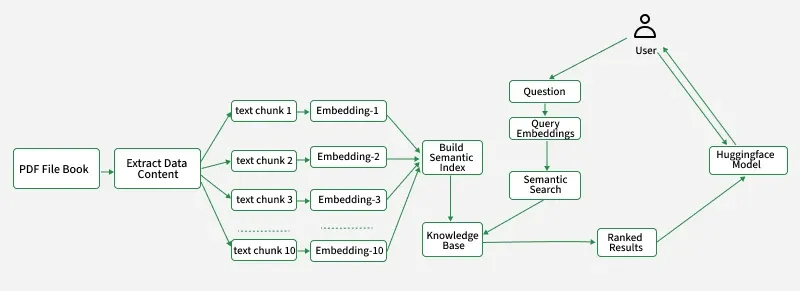

# 1. Importing Required Libraries

In [4]:
! uv pip install PyPDF2 

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Resolved 1 package in 77ms
Installed 1 package in 26ms
 + pypdf2==3.0.1


In [7]:
import os
from dotenv import load_dotenv
from PyPDF2 import PdfReader
from langchain_text_splitters import CharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings, HuggingFaceEndpoint
from langchain_community.vectorstores import FAISS
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.runnables.history import RunnableWithMessageHistory
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough            # langchain_community.llms.HuggingFaceHub → langchain_huggingface.HuggingFaceEndpoint 로 수정

# 2. Loading Environment Variables

In [8]:
# Load environment variables in a file called .env
# API 키 설정 
import os
from dotenv import load_dotenv

load_dotenv(override=True)
api_key = os.getenv('OPENAI_API_KEY')
google_api_key = os.getenv('GOOGLE_API_KEY')

# Check the key
if not api_key:
    print("No API key was found - please head over to the troubleshooting notebook in this folder to identify & fix!")
elif not api_key.startswith("sk-proj-"):
    print("An API key was found, but it doesn't start sk-proj-; please check you're using the right key - see troubleshooting notebook")
elif api_key.strip() != api_key:
    print("An API key was found, but it looks like it might have space or tab characters at the start or end - please remove them - see troubleshooting notebook")
else:
    print("API key found and looks good so far!")

if google_api_key:
    print(f"Google API Key exists and begins {google_api_key[:2]}")
else:
    print("Google API Key not set (and this is optional)")

API key found and looks good so far!
Google API Key exists and begins AI


# 3. PDF Reading

In [9]:
def get_pdf_text(pdf_docs):
    text = ""
    for pdf in pdf_docs:
        pdf_reader = PdfReader(pdf)
        for page in pdf_reader.pages:
            extracted_text = page.extract_text()
            if extracted_text:
                text += extracted_text + "\n"
    return text

# 4. Text Chunking

In [10]:
def get_text_chunks(text):
    text_splitter = CharacterTextSplitter(
        separator="\n", chunk_size=1000, chunk_overlap=200, length_function=len
    )
    return text_splitter.split_text(text)

# 5. Embedding Generation and Vector Store Creation

In [11]:
from langchain_chroma import Chroma
from langchain_openai import OpenAIEmbeddings

def get_vectorstore(text_chunks):
    # OpenAI 임베딩 모델 초기화
    # text-embedding-3-large: OpenAI 최신 고성능 임베딩 모델 (벡터 차원 3072)
    # text-embedding-3-small: 경량 버전 (벡터 차원 1536, 비용 절감)
    embeddings = OpenAIEmbeddings(model="text-embedding-3-large")

    return Chroma.from_texts(
        texts=text_chunks,
        embedding=embeddings,
        persist_directory="chroma_db"  # 로컬 저장 경로 (필요 없으면 제거 가능)
    )

# 6. Conversation Chain Setup (LLM, Retriever, Memory)

In [12]:
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.runnables.history import RunnableWithMessageHistory
from langchain_core.chat_history import InMemoryChatMessageHistory
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough

# 대화 기록 저장소 (세션별 관리)
store = {}

def get_session_history(session_id: str) -> InMemoryChatMessageHistory:
    # 세션 ID별로 대화 기록을 관리
    # 동일 session_id로 호출하면 기존 기록을 유지하며 대화 연속성 보장
    if session_id not in store:
        store[session_id] = InMemoryChatMessageHistory()
    return store[session_id]


def get_conversation_chain(vectorstore):
    # ── 1. LLM 초기화 ─────────────────────────────────────────
    # HuggingFaceHub(falcon-7b) → ChatOpenAI(gpt-4.1-nano) 로 변경
    llm = ChatOpenAI(
        model_name="gpt-4.1-nano",
        temperature=0.7,
        max_tokens=512
    )

    # ── 2. Retriever 생성 ─────────────────────────────────────
    retriever = vectorstore.as_retriever()

    # ── 3. 프롬프트 템플릿 구성 ───────────────────────────────
    # MessagesPlaceholder: 대화 기록을 프롬프트에 동적으로 삽입
    prompt = ChatPromptTemplate.from_messages([
        ("system", "당신은 주어진 문서를 기반으로 질문에 답변하는 assistant입니다.\n\n문서 내용:\n{context}"),
        MessagesPlaceholder(variable_name="chat_history"),  # 이전 대화 기록 삽입
        ("human", "{question}")
    ])

    # ── 4. LCEL 체인 구성 ─────────────────────────────────────
    # ConversationalRetrievalChain → LCEL 파이프라인으로 대체
    chain = (
        {
            "context": retriever,           # 질문 기반으로 관련 문서 검색
            "question": RunnablePassthrough(),  # 질문을 그대로 전달
            "chat_history": RunnablePassthrough()  # 대화 기록 전달
        }
        | prompt
        | llm
        | StrOutputParser()
    )

    # ── 5. 대화 기록 관리 래핑 ────────────────────────────────
    # RunnableWithMessageHistory: 체인에 자동 대화 기록 저장/불러오기 기능 추가
    # ConversationBufferMemory 대체
    conversation_chain = RunnableWithMessageHistory(
        chain,
        get_session_history,            # 세션별 기록 반환 함수
        input_messages_key="question",  # 사용자 입력 키
        history_messages_key="chat_history"  # 대화 기록 키
    )

    return conversation_chain

# 7. User Input Handler (Ask Questions and Display Chat)

In [14]:
def handle_userinput(user_question, chat_history):
    # ── 1. 대화 체인 초기화 여부 확인 ────────────────────────
    # PDF 업로드 전에 질문하면 경고 메시지를 chat_history에 추가 후 반환
    if conversation_chain is None:
        chat_history.append(("⚠️ PDF를 먼저 업로드하고 처리해주세요.", None))
        return chat_history

    # ── 2. 체인 실행 ──────────────────────────────────────────
    # invoke() + session_id 전달 방식으로 대화 기록 자동 관리
    response = conversation_chain.invoke(
        {"question": user_question},
        config={"configurable": {"session_id": "gradio_session"}}
    )

    # ── 3. 대화 기록 업데이트 ─────────────────────────────────
    # Gradio Chatbot은 (사용자 메시지, AI 답변) 튜플 리스트로 관리
    chat_history.append((user_question, response))

    return chat_history




# 8. User Interface 

In [16]:
import gradio as gr
# ── Gradio UI 구성 ────────────────────────────────────────────
with gr.Blocks() as demo:
    gr.Markdown("## 📄 PDF 기반 대화형 질의응답")

    # 대화 기록 표시 영역
    chatbot = gr.Chatbot(label="대화 내용", height=450)

    with gr.Row():
        # 질문 입력창
        user_input = gr.Textbox(
            label="질문 입력",
            placeholder="질문을 입력하세요...",
            scale=4
        )
        # 전송 버튼
        send_btn = gr.Button("전송 ➤", variant="primary", scale=1)

    # 대화 초기화 버튼
    clear_btn = gr.ClearButton([chatbot, user_input], value="🗑️ 대화 초기화")

    # ── 이벤트 연결 ───────────────────────────────────────────
    # 전송 버튼 클릭 시 handle_userinput 실행 → 입력창 초기화
    send_btn.click(
        fn=handle_userinput,
        inputs=[user_input, chatbot],
        outputs=[chatbot]
    ).then(
        fn=lambda: "",      # 전송 후 입력창 자동 비우기
        outputs=[user_input]
    )

    # Enter 키로도 질문 전송 가능
    user_input.submit(
        fn=handle_userinput,
        inputs=[user_input, chatbot],
        outputs=[chatbot]
    ).then(
        fn=lambda: "",
        outputs=[user_input]
    )

demo.launch(share=False)

C:\Users\jino7\AppData\Local\Temp\ipykernel_32400\3873398541.py:7: UserWarning: You have not specified a value for the `type` parameter. Defaulting to the 'tuples' format for chatbot messages, but this is deprecated and will be removed in a future version of Gradio. Please set type='messages' instead, which uses openai-style dictionaries with 'role' and 'content' keys.
  chatbot = gr.Chatbot(label="대화 내용", height=450)


* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


Traceback (most recent call last):
  File "c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\queueing.py", line 759, in process_events
    response = await route_utils.call_process_api(
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\route_utils.py", line 354, in call_process_api
    output = await app.get_blocks().process_api(
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\blocks.py", line 2116, in process_api
    result = await self.call_function(
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jino7\Desktop\llm_engineering-main\.venv\Lib\site-packages\gradio\blocks.py", line 1623, in call_function
    prediction = await anyio.to_thread.run_sync(  # type: ignore
                 ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jino7\Desktop\llm_engineering-main\.venv\